In [8]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
trainY, testY = load_mnist_dataset(root='/workspace/aim-bridges-data/mnist', download=False)

In [3]:
def remove_module_prefix(state_dict):
    """Remove 'module.' prefix from state_dict keys.
    it gets added when using DataParallel"""
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('module.'):
            new_state_dict[k[7:]] = v  # Remove 'module.' prefix
        else:
            new_state_dict[k] = v
    return new_state_dict

In [4]:
model = UNet()

In [29]:
# Use DataParallel to wrap the model for multi-GPU training
#if torch.cuda.device_count() > 1:
#    print(f"Using {torch.cuda.device_count()} GPUs for sampling")
#    model = nn.DataParallel(model)

In [5]:
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_64_T_1.0_stoch_checkpoint_n_batch_14000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_64_T_1.0_stoch_checkpoint_n_batch_14000.pth'


<All keys matched successfully>

In [9]:
T = 1.
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

In [10]:
samples = diffusion_model.sampling(n_samples=1, use_tqdm=True, n_steps=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
100%|██████████| 1000/1000 [00:16<00:00, 61.78it/s]


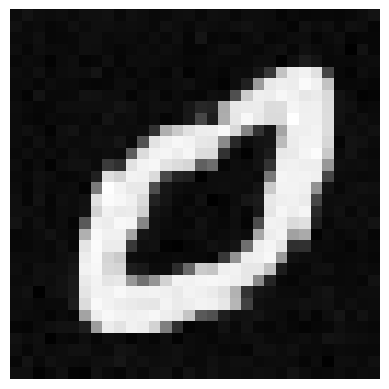

In [11]:
view_image(samples.cpu()[0])